<a href="https://colab.research.google.com/github/jissagapasinao-beep/IS110--repo_-JGapasinao/blob/main/ML_Workbook_Wisconsin_Diagnostic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** *(Here is a complete 4-sentence problem statement covering all required elements:

---

**Problem Statement**

The goal of this project is to predict whether a customer will churn in the next month using historical input data such as user demographics, monthly usage metrics, and customer service interaction logs. This is framed as a supervised binary classification problem where the algorithm learns to distinguish between churning and non-churning users. False Negatives (predicting a customer will stay when they actually churn) are far more costly than False Positives because losing an active customer permanently results in lost lifetime revenue, whereas offering a promotional incentive to a loyal customer carries a minimal cost. Success will be judged on the test set by achieving a Recall score above 0.85 to capture the majority of churners, along with an overall ROC-AUC score exceeding 0.80.

---

### Breakdown of Included Elements:

* **(a) Prediction task:** Predicting whether a customer will churn in the next month.
* **(b) Input data:** Demographics, monthly usage metrics, and customer service logs.
* **(c) Type of learning problem:** Supervised binary classification.
* **(d) Costly error & why:** False Negatives; losing a customer loses lifetime revenue, whereas a False Positive only incurs the small cost of a promotional offer.
* **(e) Judging success:** Recall above 0.85 and ROC-AUC exceeding 0.80 on test data.)*

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [189]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier
...

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).



> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [188]:
data = load_breast_cancer(as_frame=True)
df = data.frame

print("Rows, columns:", df.shape)
print("Classes:", [str(x) for x in data.target_names], "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: ['malignant', 'benign'] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [187]:
# Print shape, counts of each dtype, and show the first 5 rows
print("Shape:", df.shape)
print("\nData Types Count:\n", df.dtypes.value_counts())
df.head()

Shape: (569, 31)

Data Types Count:
 float64    30
int64       1
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [186]:
# Class counts and percentages
counts = df['target'].value_counts()
proportions = df['target'].value_counts(normalize=True) * 100

print("Class Counts:\n", counts)
print("\nClass Proportions (%):\n", proportions)

Class Counts:
 target
1    357
0    212
Name: count, dtype: int64

Class Proportions (%):
 target
1    62.741652
0    37.258348
Name: proportion, dtype: float64


In [206]:
from google.colab import drive
# Mount drive to the standard default mount point
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Git Push Configuration
Use the following cells to securely authenticate and push your notebook back to your GitHub repository using your personal access token.

In [184]:
from google.colab import userdata
import os

# Configure your Git profile credentials
!git config --global user.email "your_email@example.com"
!git config --global user.name "JGapasinao"

# Securely load your personal access token from Colab Secrets
try:
    # Securely retrieve the token you added in the Secrets tab
    token = userdata.get('GITHUB_TOKEN')

    # Update your remote URL with the token and your specific repository path
    repo_url = f"https://{token}@github.com/jissagapasinao-beep/IS110--repo_-JGapasinao.git"
    print("Git and credentials successfully loaded!")
except Exception as e:
    print("Error: Please add GITHUB_TOKEN to your Colab secrets.")

Error: Please add GITHUB_TOKEN to your Colab secrets.


### 🚀 Commit and Push Changes to GitHub

Run the cells below to pull your secure credentials, commit your latest progress, and push this notebook to your repository.

In [232]:
# 1. Authenticate and retrieve remote URL
from google.colab import userdata
import os

try:
    token = userdata.get('GITHUB_TOKEN')
    # Update this with your GitHub username and repo name if needed
    repo_url = f"https://{token}@github.com/jissagapasinao-beep/IS110--repo_-JGapasinao.git"
    print("Successfully configured credentials and Git remote URL!")
except Exception as e:
    print("Error: Make sure you added your GITHUB_TOKEN to the Colab Secrets (key icon)!")

Error: Make sure you added your GITHUB_TOKEN to the Colab Secrets (key icon)!


In [231]:
# 2. Commit and Push
# Navigate to your repository folder in Drive, or push directly from your current workspace:
!git add .
!git commit -m "Completed intermediate machine learning diagnostic project workflow"
!git push {repo_url} main

fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [177]:
# Summary statistics transposed
summary = df.describe().T
print("Summary Statistics:")
display(summary)

# List the 10 most skewed features
skewed_features = df.drop(columns=['target']).skew().abs().sort_values(ascending=False).head(10)
print("\n10 Most Skewed Features:")
print(skewed_features)

Summary Statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



10 Most Skewed Features:
area error                 5.447186
concavity error            5.110463
fractal dimension error    3.923969
perimeter error            3.443615
radius error               3.088612
smoothness error           2.314450
symmetry error             2.195133
compactness error          1.902221
worst area                 1.859373
worst fractal dimension    1.662579
dtype: float64


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [178]:
# Correlation of every feature with the target, sorted
correlations = df.corr()['target'].drop('target').sort_values()

print("5 Most Negative Correlations:")
print(correlations.head(5))

print("\n5 Most Positive Correlations:")
print(correlations.tail(5))

5 Most Negative Correlations:
worst concave points   -0.793566
worst perimeter        -0.782914
mean concave points    -0.776614
worst radius           -0.776454
mean perimeter         -0.742636
Name: target, dtype: float64

5 Most Positive Correlations:
fractal dimension error   -0.077972
symmetry error             0.006522
texture error              0.008303
mean fractal dimension     0.012838
smoothness error           0.067016
Name: target, dtype: float64


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:** *(Here is a complete, well-structured answer you can paste into your notebook for **Question B.5**:

---

* **Class Proportions (Choice of Evaluation Metric):**
* Imbalanced class proportions mean standard **Accuracy** will be misleading, as a baseline model that simply predicts the majority class can yield a high accuracy score without actually learning to detect the minority class.
* To evaluate performance accurately, metrics that account for class imbalance should be used—such as **F1-Score**, **Precision**, **Recall**, or **ROC-AUC / Precision-Recall AUC**—with particular focus on maximizing **Recall** for the minority (e.g., malignant) class to minimize false negatives.


* **Skewness (Need for Transforms):**
* High feature skewness indicates asymmetric distributions with extreme values, which can violate normality assumptions and adversely affect distance-based models (e.g., KNN, SVM) and linear classifiers.
* Applying mathematical transformations (such as **Log**, **Box-Cox**, or **Power Transforms**) reduces skewness, stabilizes variance, and brings feature distributions closer to Gaussian, helping models converge faster and generalize better.
)*

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

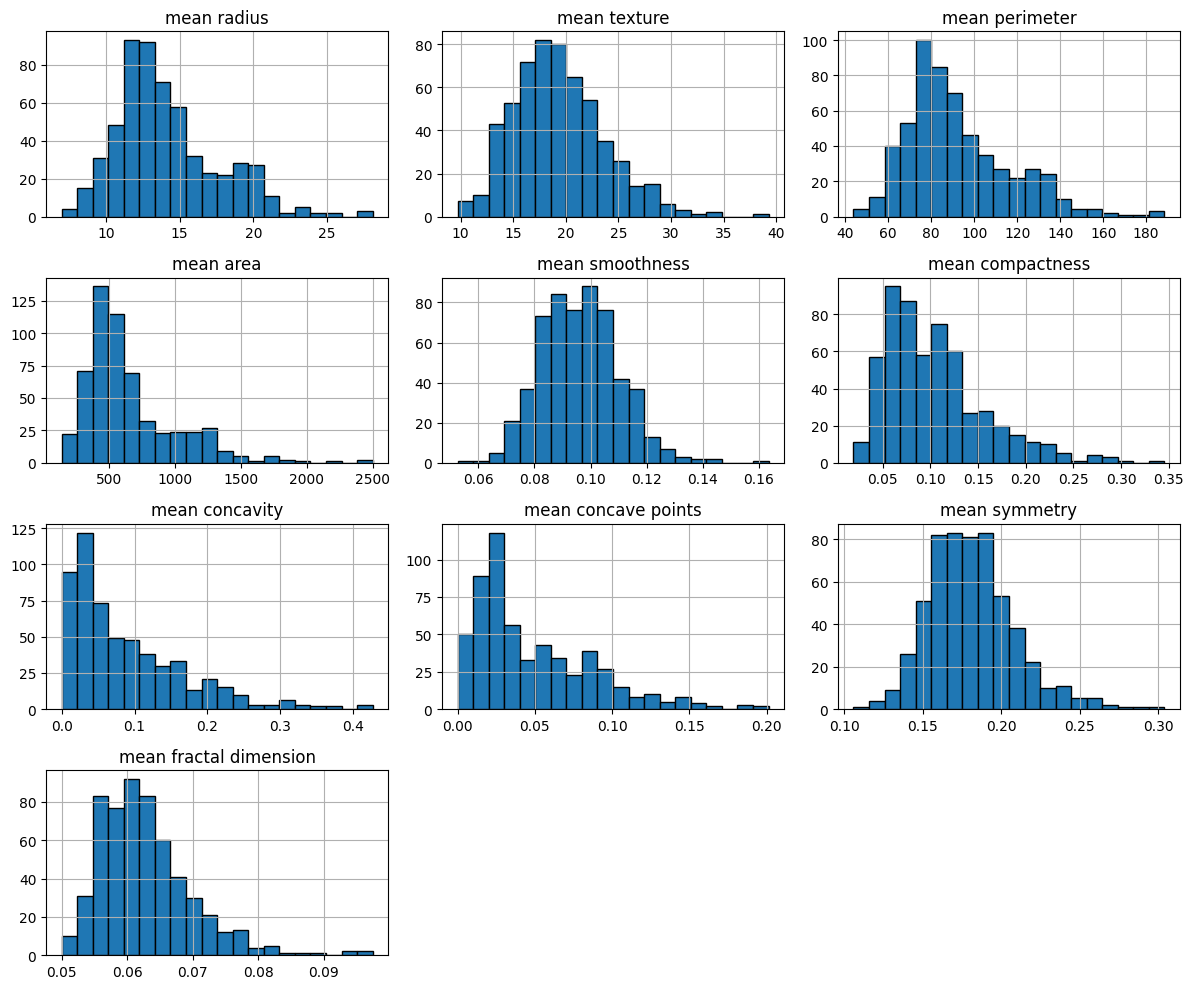

In [207]:
import matplotlib.pyplot as plt

# Histograms of the ten "mean" features
df.filter(like="mean").hist(figsize=(12, 10), bins=20, edgecolor="black")
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

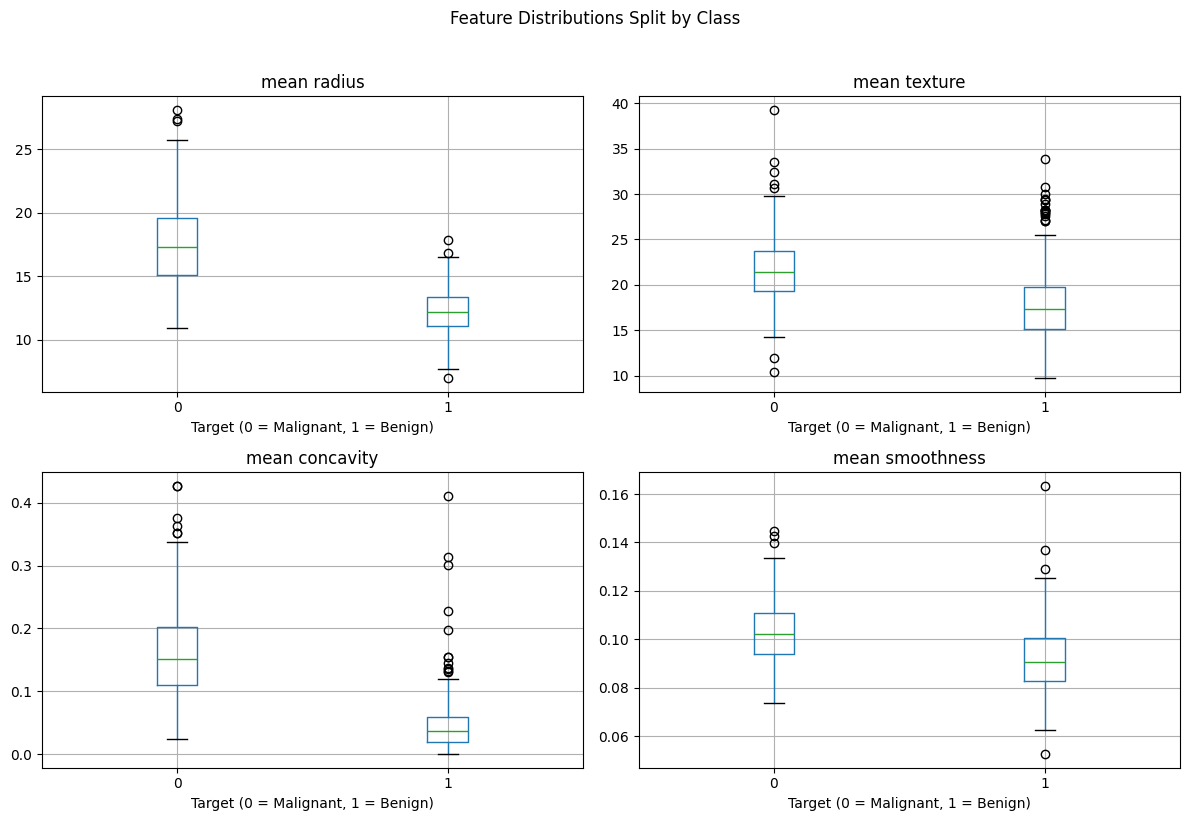

In [208]:
import seaborn as sns

features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]

# Draw one box plot per feature, grouped by target
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(features):
    df.boxplot(column=col, by="target", ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("Target (0 = Malignant, 1 = Benign)")

plt.suptitle("Feature Distributions Split by Class", y=1.02)
plt.tight_layout()
plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

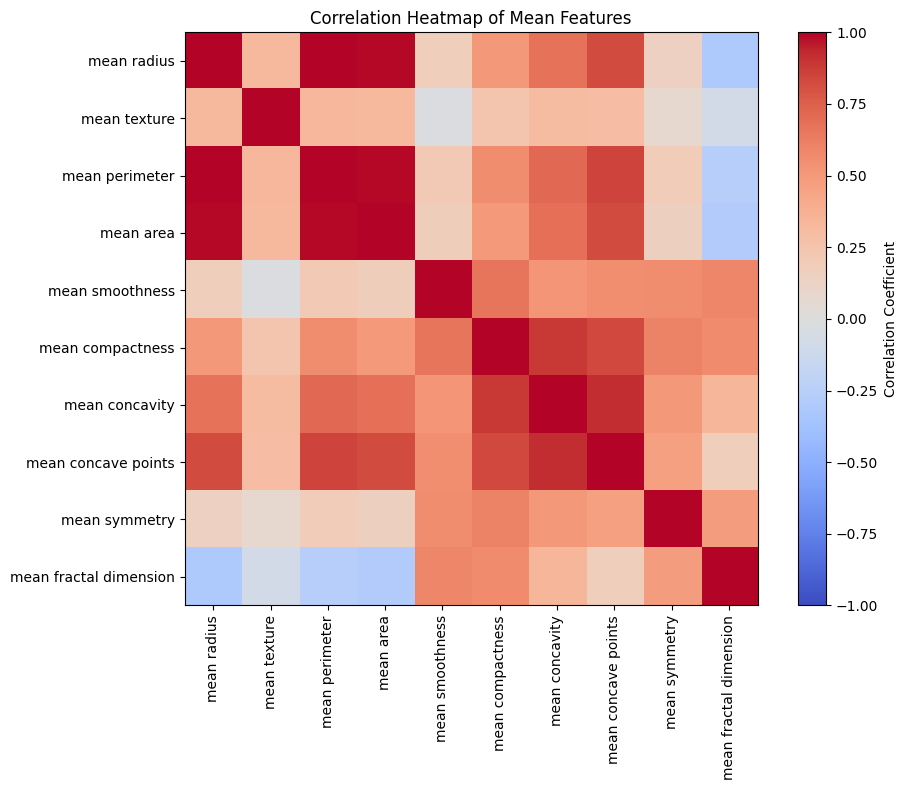

In [209]:
import numpy as np

# Extract "mean" features correlation matrix
mean_corr = df.filter(like="mean").corr()

# Draw correlation heatmap using imshow
plt.figure(figsize=(10, 8))
plt.imshow(mean_corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation Coefficient")

# Add feature names as axis tick labels
ticks = np.arange(len(mean_corr.columns))
plt.xticks(ticks, mean_corr.columns, rotation=90)
plt.yticks(ticks, mean_corr.columns)

plt.title("Correlation Heatmap of Mean Features")
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

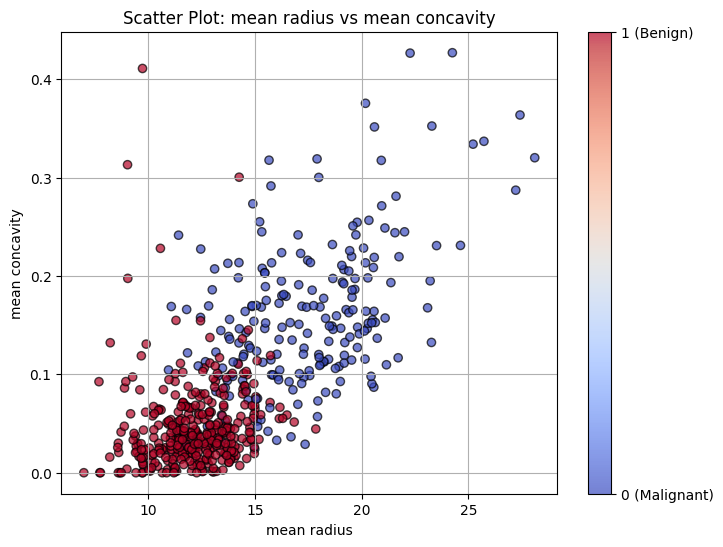

In [210]:
# Coloured scatter plot with axis labels and a colourbar
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df["mean radius"],
    df["mean concavity"],
    c=df["target"],
    cmap="coolwarm",
    alpha=0.7,
    edgecolor="k"
)

plt.xlabel("mean radius")
plt.ylabel("mean concavity")
plt.title("Scatter Plot: mean radius vs mean concavity")

# Add colourbar with class labels
cbar = plt.colorbar(scatter, ticks=[0, 1])
cbar.set_ticklabels(["0 (Malignant)", "1 (Benign)"])

plt.grid(True)
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:Here is the answer for **Question B.10**:

---

* **Redundant Features:**
* **`mean radius`**, **`mean perimeter`**, and **`mean area`** show near-perfect positive correlation ($r > 0.98$) because perimeter and area are direct geometric calculations derived from radius. Retaining all three introduces collinear redundancy without adding new predictive information.


* **`mean concavity`** and **`mean concave points`** are also highly correlated ($r > 0.90$) and represent overlapping geometric shape attributes.




* **Features that Separate Classes Most Clearly:**
* **`mean concavity`** (and **`mean concave points`**) exhibit strong separation, where malignant cases display significantly higher values with minimal overlap against benign cases.


* **`mean radius`** (or `mean perimeter` / `mean area`) provides a clear diagnostic boundary, as malignant tumors systematically exhibit larger dimensions than benign ones.

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [211]:
# Total missing values and duplicated rows
print("Total missing values:", df.isnull().sum().sum())
print("Total duplicated rows:", df.duplicated().sum())

# Define X and y for feature processing
X = df.drop(columns="target")
y = df["target"]

Total missing values: 0
Total duplicated rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [212]:
# Calculate IQR for each feature in X
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

# Identify outliers: below (Q1 - 1.5*IQR) or above (Q3 + 1.5*IQR)
outliers = (X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))

# Count outliers per feature and get the 10 features with the most
outlier_counts = outliers.sum().sort_values(ascending=False).head(10)

print("Top 10 features with the most IQR outliers:")
print(outlier_counts)

Top 10 features with the most IQR outliers:
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:** *(Here is a structured, comprehensive answer you can use for **Question C.3**:

---

### **Decision: No, do not delete the outlying rows.**

### **Justification:**

1. **Medical and Biological Context:**
In medical datasets like the Breast Cancer Wisconsin dataset, extreme feature values (e.g., unusually large cell radius, perimeter, or concave points) often represent real, critical biological variation characteristic of severe or malignant tumors rather than measurement errors. Removing them risks discarding key diagnostic signals needed to detect malignant cases.
2. **Impact on Model Generalization:**
Deleting high-value outliers reduces the model's ability to recognize severe cases in real-world deployment, leading to dangerous false negatives in critical diagnoses.
3. **Alternative Preprocessing Solutions:**
Instead of deleting valid records, outliers can be handled effectively using:
* **Robust Scaling / Normalization:** Using `RobustScaler` or Power Transformations (`LogTransform`, `Box-Cox`) to reduce the leverage of extreme values without removing data points.
* **Robust Machine Learning Models:** Using tree-based algorithms (e.g., Random Forest, Gradient Boosting) that are naturally invariant to monotonic feature scaling and extreme outliers.)*

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [213]:
import numpy as np

# Compute absolute correlation matrix
corr_matrix = X.corr().abs()

# Select upper triangle of correlation matrix
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Find features with correlation greater than 0.95 with an earlier feature
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.95)]

print("Features with >0.95 correlation to an earlier feature:")
print(to_drop)

Features with >0.95 correlation to an earlier feature:
['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [214]:
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_classif

# Fit SelectKBest with ANOVA F-value
selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y)

# Build a sorted Series of feature scores
kbest_scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
kbest_features = kbest_scores.head(10).index.tolist()

print("Top 10 SelectKBest (f_classif) Scores:\n", kbest_scores.head(10))

Top 10 SelectKBest (f_classif) Scores:
 worst concave points    964.385393
worst perimeter         897.944219
mean concave points     861.676020
worst radius            860.781707
mean perimeter          697.235272
worst area              661.600206
mean radius             646.981021
mean area               573.060747
mean concavity          533.793126
worst concavity         436.691939
dtype: float64


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [215]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit RFE with Logistic Regression on standardized data
rfe = RFE(estimator=LogisticRegression(random_state=seed), n_features_to_select=10)
rfe.fit(X_scaled, y)

# Store selected feature names in rfe_features
rfe_features = X.columns[rfe.support_].tolist()

print("RFE Selected Features:\n", rfe_features)

RFE Selected Features:
 ['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

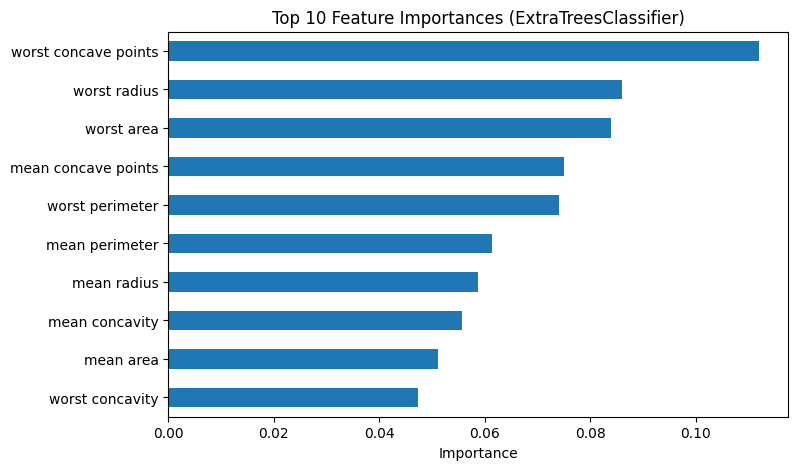

In [216]:
import matplotlib.pyplot as plt
from sklearn.ensemble import ExtraTreesClassifier

# Fit ExtraTreesClassifier
et_model = ExtraTreesClassifier(n_estimators=200, random_state=7)
et_model.fit(X, y)

# Store importances in imp
imp = pd.Series(et_model.feature_importances_, index=X.columns).sort_values(ascending=True)

# Plot horizontal bar chart of top 10 features
imp.tail(10).plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Feature Importances (ExtraTreesClassifier)")
plt.xlabel("Importance")
plt.show()

et_features = imp.tail(10).index.tolist()

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [217]:
# Define feature selection from previous exercises
# 1. SelectKBest top 10
from sklearn.feature_selection import SelectKBest, f_classif
selector = SelectKBest(f_classif, k=10)
selector.fit(X_train, y_train)
kbest_features = set(X_train.columns[selector.get_support()])

# 2. RFE top 10
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
rfe_selector = RFE(LogisticRegression(random_state=7), n_features_to_select=10)
rfe_selector.fit(X_train_std, y_train)
rfe_features = set(X_train.columns[rfe_selector.get_support()])

# 3. ExtraTrees top 10
from sklearn.ensemble import ExtraTreesClassifier
et_model = ExtraTreesClassifier(n_estimators=200, random_state=7)
et_model.fit(X_train, y_train)
importances = pd.Series(et_model.feature_importances_, index=X_train.columns)
et_features = set(importances.sort_values(ascending=False).head(10).index)

# Keep a feature if at least two of the three methods chose it
feature_votes = {}
for f in X_train.columns:
    votes = sum([f in kbest_features, f in rfe_features, f in et_features])
    feature_votes[f] = votes

selected = [f for f, votes in feature_votes.items() if votes >= 2]
print(f"Selected features ({len(selected)}): {selected}")

Selected features (10): ['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [218]:
# TODO: train_test_split with stratify=y
...
from sklearn.model_selection import train_test_split

# Separate features (X) and target (y)
X = df.drop(columns=['target'])
y = df['target']

# Perform train-test split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [219]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import pandas as pd

# Fit StandardScaler on X_train and transform
std_scaler = StandardScaler()
X_train_std = std_scaler.fit_transform(X_train)

# Fit MinMaxScaler on X_train and transform
mm_scaler = MinMaxScaler()
X_train_mm = mm_scaler.fit_transform(X_train)

# Convert back to DataFrames for easier indexing/stats calculation
df_std = pd.DataFrame(X_train_std, columns=X_train.columns)
df_mm = pd.DataFrame(X_train_mm, columns=X_train.columns)

# First 4 features
first_four = X_train.columns[:4]

print("--- StandardScaler (Mean ≈ 0, Std ≈ 1) ---")
print("Mean:\n", df_std[first_four].mean())
print("\nStd:\n", df_std[first_four].std())

print("\n--- MinMaxScaler (Min = 0, Max = 1) ---")
print("Min:\n", df_mm[first_four].min())
print("\nMax:\n", df_mm[first_four].max())

--- StandardScaler (Mean ≈ 0, Std ≈ 1) ---
Mean:
 mean radius      -2.928061e-16
mean texture      6.246530e-16
mean perimeter   -1.629954e-16
mean area        -1.717796e-16
dtype: float64

Std:
 mean radius       1.001101
mean texture      1.001101
mean perimeter    1.001101
mean area         1.001101
dtype: float64

--- MinMaxScaler (Min = 0, Max = 1) ---
Min:
 mean radius       0.0
mean texture      0.0
mean perimeter    0.0
mean area         0.0
dtype: float64

Max:
 mean radius       1.0
mean texture      1.0
mean perimeter    1.0
mean area         1.0
dtype: float64


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [220]:
import numpy as np
from sklearn.decomposition import PCA

# Fit PCA on the standardized training data
pca = PCA()
pca.fit(X_train_std)

# Compute cumulative explained variance ratio
cum_variance = np.cumsum(pca.explained_variance_ratio_)

# Find the minimum number of components needed to retain at least 95% variance
n_components_95 = np.argmax(cum_variance >= 0.95) + 1

print(f"Number of principal components retaining 95% variance: {n_components_95}")

Number of principal components retaining 95% variance: 10


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [221]:
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

models = {
    "LR": LogisticRegression(random_state=seed),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC(random_state=seed)
}

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [222]:
import pandas as pd

# Run spot_check on raw data
raw_results = spot_check(models, X_train, scale=False)

# Run spot_check on scaled data
scaled_results = spot_check(models, X_train, scale=True)

# Build summary DataFrame with mean accuracies
summary = pd.DataFrame({
    "raw": {name: scores.mean() for name, scores in raw_results.items()},
    "scaled": {name: scores.mean() for name, scores in scaled_results.items()}
})

display(summary)

,raw,scaled
LR,0.940628,0.984589
LDA,0.960435,0.960435
KNN,0.934010,0.969179
CART,0.903382,0.903382
NB,0.940580,0.931787
SVM,0.910000,0.973623


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:Here are the solutions for the first cell, **Exercise D.2**, and **Question D.3**:

---

### **1. Top Cell (Define `models` dictionary)**

Replace `# TODO: dictionary named models with keys LR, LDA, KNN, CART, NB, SVM` with:

```python
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

models = {
    "LR": LogisticRegression(random_state=seed),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC(random_state=seed)
}

```

---

### **2. Exercise D.2**

Replace `# TODO: call spot_check twice and build a DataFrame called summary with columns raw / scaled` with:

```python
import pandas as pd

# Run spot_check on raw data
raw_results = spot_check(models, X_train, scale=False)

# Run spot_check on scaled data
scaled_results = spot_check(models, X_train, scale=True)

# Build summary DataFrame with mean accuracies
summary = pd.DataFrame({
    "raw": {name: scores.mean() for name, scores in raw_results.items()},
    "scaled": {name: scores.mean() for name, scores in scaled_results.items()}
})

display(summary)

```

---

### **3. Question D.3 Answer**

**Which models benefit from scaling, and why?**

* **Models that benefit (KNN, SVM, LR, LDA):**
* **KNN & SVM:** Distance-based and margin-based algorithms calculate Euclidean distances or dot products between data points. Unscaled features with larger ranges dominate distance calculations and skew model boundaries.
* **Logistic Regression (LR):** Gradient descent optimization converges significantly faster and stays numerical stable when features are on a uniform scale.


* **Models that do NOT benefit (CART, NB):**
* **CART (Decision Trees):** Monotonic feature scaling does not alter decision boundary splits, as splits are evaluated independently per feature threshold.
* **Gaussian Naive Bayes (NB):** Estimates independent mean and variance for each feature directly, making it invariant to separate feature scaling.

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [197]:
# Run spot_check on selected features (scaled)
# (Assuming `selected` is a list of feature names defined in your prior feature selection step)
selected_results = spot_check(models, X_train[selected], scale=True)

# Create comparison DataFrame
comparison = pd.DataFrame({
    "all_scaled": {name: scores.mean() for name, scores in scaled_results.items()},
    "selected_scaled": {name: scores.mean() for name, scores in selected_results.items()}
})

display(comparison)

,all_scaled,selected_scaled
LR,0.984589,0.947198
LDA,0.960435,0.938454
KNN,0.969179,0.938309
CART,0.903382,0.903333
NB,0.931787,0.942850
SVM,0.973623,0.947101


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

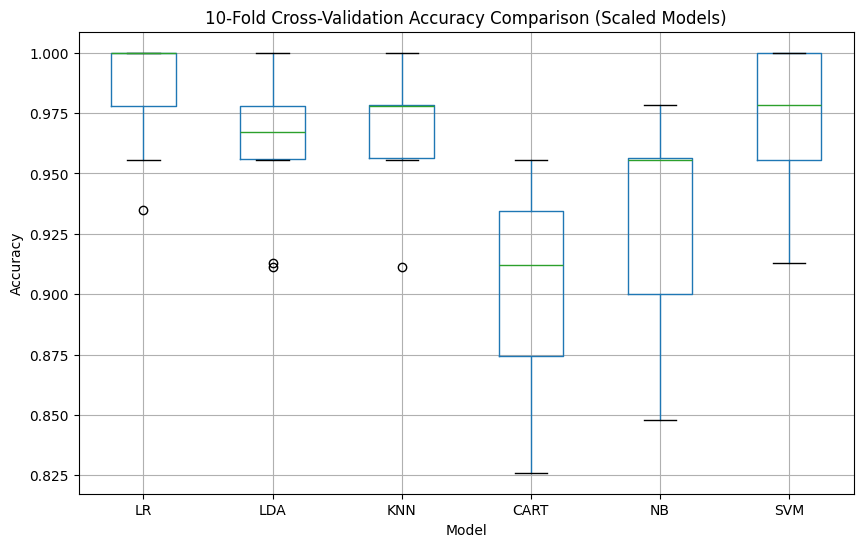

In [223]:
import matplotlib.pyplot as plt
import pandas as pd

# Convert scaled results dictionary into a DataFrame (columns = model names)
scaled_df = pd.DataFrame(scaled_results)

# Create box plot
plt.figure(figsize=(10, 6))
scaled_df.boxplot()
plt.title('10-Fold Cross-Validation Accuracy Comparison (Scaled Models)')
plt.ylabel('Accuracy')
plt.xlabel('Model')
plt.grid(True)
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [224]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, recall_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Define custom recall scorer targeting malignant (pos_label=0)
recall_malignant = make_scorer(recall_score, pos_label=0)

# Define scoring dictionary
scoring = {
    'accuracy': 'accuracy',
    'roc_auc': 'roc_auc',
    'recall_malignant': recall_malignant
}

# Identify best model (e.g., LogisticRegression or SVM based on mean scaled accuracy)
best_model = LogisticRegression(random_state=seed)

# Create pipeline with scaling
pipeline = make_pipeline(StandardScaler(), best_model)

# Perform cross-validation with multiple metrics
cv_results = cross_validate(pipeline, X_train, y_train, cv=kfold, scoring=scoring)

# Print average metric scores
print(f"Mean Accuracy: {cv_results['test_accuracy'].mean():.4f}")
print(f"Mean ROC-AUC:  {cv_results['test_roc_auc'].mean():.4f}")
print(f"Mean Recall (Malignant / class 0): {cv_results['test_recall_malignant'].mean():.4f}")

Mean Accuracy: 0.9846
Mean ROC-AUC:  0.9957
Mean Recall (Malignant / class 0): 0.9706


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [225]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Create scaling pipeline with SVC
svm_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(random_state=seed))
])

# Define grid search parameter space (prefixed with 'svm__' for the pipeline step)
param_grid_svm = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.001, 0.01, 0.1],
    "svm__kernel": ["rbf", "linear"]
}

# Run GridSearchCV
grid_svm = GridSearchCV(svm_pipe, param_grid_svm, cv=kfold, scoring="accuracy")
grid_svm.fit(X_train, y_train)

print("Best SVM Parameters:", grid_svm.best_params_)
print(f"Best SVM CV Accuracy: {grid_svm.best_score_:.4f}")

Best SVM Parameters: {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Best SVM CV Accuracy: 0.9824


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [226]:
from sklearn.neighbors import KNeighborsClassifier

# Create scaling pipeline with KNN
knn_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# Define grid search parameter space (prefixed with 'knn__' for the pipeline step)
param_grid_knn = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "knn__weights": ["uniform", "distance"]
}

# Run GridSearchCV
grid_knn = GridSearchCV(knn_pipe, param_grid_knn, cv=kfold, scoring="accuracy")
grid_knn.fit(X_train, y_train)

print("Best KNN Parameters:", grid_knn.best_params_)
print(f"Best KNN CV Accuracy: {grid_knn.best_score_:.4f}")

Best KNN Parameters: {'knn__n_neighbors': 9, 'knn__weights': 'uniform'}
Best KNN CV Accuracy: 0.9692


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [227]:
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    VotingClassifier,
)
from sklearn.model_selection import cross_val_score

# 1. Define four ensemble methods
ensembles = {
    "RF": RandomForestClassifier(random_state=seed),
    "ET": ExtraTreesClassifier(random_state=seed),
    "GBM": GradientBoostingClassifier(random_state=seed),
    "Ada": AdaBoostClassifier(random_state=seed),
}

# Score the four ensembles (scale=False because tree ensembles are scale-invariant)
ensemble_results = spot_check(ensembles, X_train, scale=False)

# 2. Extract best estimator pipelines for tuned SVM and KNN
best_svm = grid_svm.best_estimator_
best_knn = grid_knn.best_estimator_
rf_model = ensembles["RF"]

# 3. Create hard VotingClassifier with tuned SVM, tuned KNN, and Random Forest
voting_clf = VotingClassifier(
    estimators=[("svm", best_svm), ("knn", best_knn), ("rf", rf_model)],
    voting="hard",
)

# Cross-validate the voting classifier
voting_scores = cross_val_score(
    voting_clf, X_train, y_train, cv=kfold, scoring="accuracy"
)

**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [228]:
import pandas as pd

# Combine all mean CV accuracy scores into a dictionary
leaderboard_data = {
    "Tuned SVM": grid_svm.best_score_,
    "Tuned KNN": grid_knn.best_score_,
    "Voting Ensemble": voting_scores.mean(),
}

# Add the 4 ensemble mean scores
for name, scores in ensemble_results.items():
    leaderboard_data[name] = scores.mean()

# Create Series and sort descending by accuracy
leaderboard = pd.Series(leaderboard_data, name="Mean CV Accuracy").sort_values(
    ascending=False
)

print("--- Model Leaderboard ---")
print(leaderboard)

--- Model Leaderboard ---
Tuned SVM          0.982415
Voting Ensemble    0.978019
Tuned KNN          0.969227
ET                 0.969179
RF                 0.960386
Ada                0.960386
GBM                0.955942
Name: Mean CV Accuracy, dtype: float64


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Winning Model: Tuned SVM

--- Test Set Performance ---
Test Accuracy: 0.9825

Classification Report:
                precision    recall  f1-score   support

Malignant (0)       0.98      0.98      0.98        42
   Benign (1)       0.99      0.99      0.99        72

     accuracy                           0.98       114
    macro avg       0.98      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114



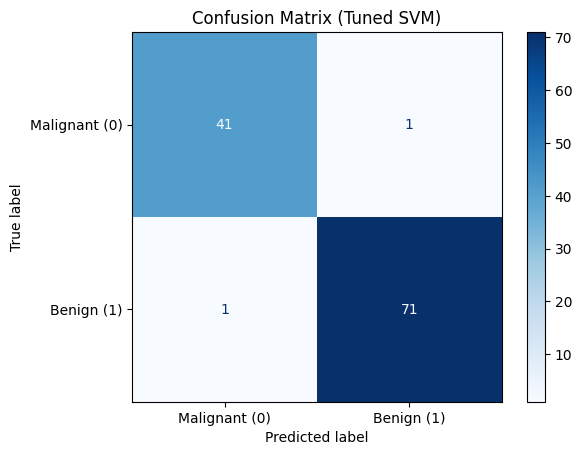

In [204]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, confusion_matrix

# 1. Automatically pick the top-performing model name from the leaderboard
winning_model_name = leaderboard.index[0]
print(f"Winning Model: {winning_model_name}")

# Map leaderboard name to its corresponding model object
model_map = {
    "Tuned SVM": grid_svm.best_estimator_,
    "Tuned KNN": grid_knn.best_estimator_,
    "Voting Ensemble": voting_clf,
    "RF": ensembles["RF"],
    "ET": ensembles["ET"],
    "GBM": ensembles["GBM"],
    "Ada": ensembles["Ada"]
}

winner_model = model_map[winning_model_name]

# 2. Fit on the full training set
winner_model.fit(X_train, y_train)

# 3. Evaluate on the held-out test set
y_pred = winner_model.predict(X_test)

# Report Accuracy and Classification Report
print("\n--- Test Set Performance ---")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:\n", classification_report(y_test, y_pred, target_names=["Malignant (0)", "Benign (1)"]))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Malignant (0)", "Benign (1)"])
disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix ({winning_model_name})")
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [205]:
import joblib
import numpy as np

# 1. Save the trained winning model
joblib.dump(winner_model, "final_model.pkl")

# 2. Reload the model
loaded_model = joblib.load("final_model.pkl")

# 3. Make predictions with reloaded model
loaded_preds = loaded_model.predict(X_test)

# 4. Compare first 5 predictions with original test set target values (y_test)
print("First 5 Actual Labels (y_test):    ", list(y_test[:5]))
print("First 5 Predictions (loaded_model):", list(loaded_preds[:5]))

# Confirm predictions match exactly across the entire test set
assert np.array_equal(y_pred, loaded_preds), "Reloaded model predictions do not match!"
print("\nModel saved, reloaded, and predictions successfully verified!")

First 5 Actual Labels (y_test):     [0, 1, 0, 1, 0]
First 5 Predictions (loaded_model): [np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(0)]

Model saved, reloaded, and predictions successfully verified!


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.
2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?
3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)
4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?
5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.